# Simulation Analysis Guide

This notebook shows, step by step, how to read and analyse the ROOT files of
`Muon_Simulation`. It is a guide, not a result: the example files are small,
so the numbers below have large statistical errors.

What is covered:

| Section | Topic | Example file |
| --- | --- | --- |
| 1 | What is inside a file | `flat_mode0.root` |
| 2 | `RunInfo` and the live time | `flat_mode0.root` |
| 3 | Generated muons (`Primaries`) | `flat_mode0.root` |
| 4 | Panel hits: steps, events, energy deposit | `flat_mode0.root` |
| 5 | Coincidences and thresholds | `flat_mode0.root` |
| 6 | Rate with uncertainty | `flat_mode0.root` |
| 7 | Which particle fired the panels | `flat_mode0.root` |
| 8 | Light guides (geometry mode 2) | `flat_mode2.root` |
| 9 | Zenith scan | `Scan/theta_*.root` |
| 10 | Geometric factor from the isotropic source | `isotropic_plane.root` |
| 11 | Optical photons (`-p`) | `optical_beam.root` |
| 12 | CRY showers | (only if a CRY file exists) |

### Making the example files

The files are produced by `make_guide_data.sh` (same folder). Run it from the
build directory; it takes a few minutes:

```bash
cd build
bash ../JupyterNB_Analysis_Examples/make_guide_data.sh
```

It writes the macros it uses to `build/Guide_Example/macros/`, so every file
below can be traced back to its macro. In short:

| File | Generator | Setup | Events |
| --- | --- | --- | --- |
| `flat_mode0.root` | EcoMug, sky plane 2 m x 2 m at z = 2 m, 0.1-1000 GeV/c | vertical, scintillators only | 2e5 |
| `flat_mode2.root` | same muons (same seed) | scintillators + light guides | 2e5 |
| `Scan/theta_*.root` | EcoMug, hemisphere R = 1.4 m | zenith 0, 10, 20, 30, 45, 60 deg | 2e5 each |
| `isotropic_plane.root` | cosine-law source, plane 2 m x 2 m at z = 1.3 m, 2 GeV/c | vertical | 2e6 |
| `optical_beam.root` | vertical 2 GeV/c mu- through the panel centre | mode 2, `-p`, photons stored | 10 |

### Panel numbering

In the simulation the panels are numbered 0 to 3 **from top to bottom**. In
the lab the same panels are called P1, P0, P3, P2 (top to bottom).

## 0. Setup

In [1]:
import os
import sys
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from uncertainties import ufloat
from scipy.optimize import curve_fit

# The analysis scripts of the repository live in ../analysis
sys.path.insert(0, os.path.abspath("../analysis"))
from overburden_analysis import ecomug_horizontal_flux, E_MPV

# Folder with the example files (written by make_guide_data.sh)
DATA_DIR = "../build/Guide_Example"
print("Data folder:", DATA_DIR)
print("Files:", sorted(os.path.relpath(p, DATA_DIR)
                       for p in glob.glob(f"{DATA_DIR}/**/*.root", recursive=True)))

plt.rcParams["figure.dpi"] = 110

Data folder: ../build/Guide_Example
Files: ['Scan/theta_0.root', 'Scan/theta_10.root', 'Scan/theta_20.root', 'Scan/theta_30.root', 'Scan/theta_45.root', 'Scan/theta_60.root', 'flat_mode0.root', 'flat_mode2.root', 'isotropic_plane.root', 'optical_beam.root']


In [2]:
# Geometry constants (current configuration, zenith 0)
PANEL_SIDE = 280.0          # mm, scintillator side
PANEL_HALF = 140.0          # mm, half side; in mode 2 a step with |x| > 140 mm is in the light guide
LAB_NAME   = {0: "P1", 1: "P0", 2: "P3", 3: "P2"}   # simulation panel -> lab name

# E_MPV: most probable deposit of each panel in four-fold events (MeV),
# taken from analysis/overburden_analysis.py. The usual threshold is 0.5 E_MPV.
print("E_MPV [MeV]      :", E_MPV)
print("0.5 E_MPV [MeV]  :", 0.5 * E_MPV)

E_MPV [MeV]      : [1.718 1.694 1.688 1.711]
0.5 E_MPV [MeV]  : [0.859  0.847  0.844  0.8555]


### Helper functions

These few functions are used in the whole notebook. They are short on
purpose, so that it is easy to see what they do.

In [3]:
def read_run_info(run):
    # RunInfo has one row per run. Return it as a plain dict.
    info = run["RunInfo"].arrays(library="np")
    return {key: info[key][0] for key in info}


def edep_per_event(run, n_gen, region="all"):
    # Total energy deposit per event and panel, shape (n_gen, 4), in MeV.
    #
    # Each row of PanelXHits is one Geant4 step. The detector sees the sum of
    # all steps of an event, so the steps are added with np.bincount.
    # eventID runs from 0 to n_gen - 1, so it can be used as an index.
    #
    # region: "all"   every step
    #         "scint" only steps inside the scintillator (|x| <= 140 mm)
    #         "guide" only steps inside the light guide  (|x| >  140 mm, mode 2)
    edep = np.zeros((n_gen, 4))
    for i in range(4):
        h = run[f"Panel{i}Hits"].arrays(["eventID", "edep", "x"], library="np")
        if region == "scint":
            keep = np.abs(h["x"]) <= PANEL_HALF + 1e-3
        elif region == "guide":
            keep = np.abs(h["x"]) > PANEL_HALF + 1e-3
        else:
            keep = np.ones(len(h["x"]), dtype=bool)
        edep[:, i] = np.bincount(h["eventID"][keep], weights=h["edep"][keep], minlength=n_gen)
    return edep


def four_fold(edep, threshold=0.0):
    # True for the events in which all four panels are above the threshold.
    # threshold can be one number or one value per panel.
    return np.all(edep > np.asarray(threshold), axis=1)


def rate(n, live_time):
    # Rate in Hz with its Poisson uncertainty.
    return ufloat(n, np.sqrt(n)) / live_time

## 1. What is inside a file

`uproot` reads the ROOT file without ROOT. Each ntuple is a tree; each column
is a branch.

In [4]:
run = uproot.open(f"{DATA_DIR}/flat_mode0.root")

for name in run.keys(cycle=False):
    tree = run[name]
    print(f"{name:15s} {int(tree.num_entries):9d} rows   columns: {tree.keys()}")

Panel0Hits          30134 rows   columns: ['eventID', 'trackID', 'parentID', 'pdg', 'edep', 'x', 'y', 'z', 'time', 'kineticEnergy', 'primaryID']
Panel1Hits          31018 rows   columns: ['eventID', 'trackID', 'parentID', 'pdg', 'edep', 'x', 'y', 'z', 'time', 'kineticEnergy', 'primaryID']
Panel2Hits          17174 rows   columns: ['eventID', 'trackID', 'parentID', 'pdg', 'edep', 'x', 'y', 'z', 'time', 'kineticEnergy', 'primaryID']
Panel3Hits          17976 rows   columns: ['eventID', 'trackID', 'parentID', 'pdg', 'edep', 'x', 'y', 'z', 'time', 'kineticEnergy', 'primaryID']
Coincidence        200000 rows   columns: ['eventID', 'coin_4fold', 'coin_top', 'coin_bottom', 'coin_outer', 'coincidence']
Primaries          200000 rows   columns: ['eventID', 'primaryID', 'pdg', 'energy', 'px', 'py', 'pz', 'x0', 'y0', 'z0', 'theta_deg', 'phi_deg', 't_ns']
RunInfo                 1 rows   columns: ['n_generated', 'generator', 'surface', 'source_file', 'gen_area_m2', 'flux_hz_m2', 'flux_err', 'seed'

| Tree | One row per | Notes |
| --- | --- | --- |
| `Panel0Hits` ... `Panel3Hits` | Geant4 **step** with an energy deposit | many rows per event |
| `Coincidence` | event | flags, any deposit counts (no threshold) |
| `Primaries` | generated particle | one row per event for EcoMug, several for CRY |
| `RunInfo` | run | generator, surface, area, flux, seed, live time |
| `OpticalSummary`, `PhotonHits` | event / detected photon | only with `-p` |

A tree can be read as a dict of numpy arrays or as a pandas DataFrame. Read
only the columns you need: large files are much faster that way.

In [5]:
# A dict of numpy arrays, only two columns
p0 = run["Panel0Hits"].arrays(["eventID", "edep"], library="np")
print(p0["eventID"][:10])

# A DataFrame, with a cut applied while reading
df = run["Panel0Hits"].arrays(["eventID", "pdg", "edep", "z"], cut="parentID == 0", library="pd")
df.head()

[54 54 54 54 54 54 54 54 54 54]


,eventID,pdg,edep,z
0,54,13,1.878107,1080.000000
1,54,13,0.547962,1071.645523
25,63,-13,0.406323,1080.000000
26,63,-13,1.525677,1077.989073
49,86,-13,1.348815,1080.000000


## 2. RunInfo and the live time

Every file carries the information needed for its own normalisation, so the
analysis does not have to know the macro.

In [6]:
info = read_run_info(run)
for key, value in info.items():
    print(f"{key:16s} {value}")

n_generated      200000
generator        EcoMugDirect
surface          sky
source_file      n/a
gen_area_m2      4.0
flux_hz_m2       126.80740748422956
flux_err         2.0368345298694526
seed             12345.0
live_time_s      392.43344758022096
overburden_gcm2  0.0


A simulated run corresponds to a measuring time $T$: the time in which
$N_\mathrm{gen}$ muons cross the generation surface of area $A_\mathrm{gen}$,

$$T = \frac{N_\mathrm{gen}}{\Phi \, A_\mathrm{gen}}, \qquad R = \frac{N_4}{T} = \Phi \, A_\mathrm{gen} \, \frac{N_4}{N_\mathrm{gen}} .$$

There are three ways to get $T$ for an EcoMug run, and they should agree:

1. `live_time_s` from `RunInfo` (EcoMug's own estimate).
2. `n_generated / (flux_hz_m2 * gen_area_m2)`. `flux_hz_m2` comes from a
   Monte Carlo integration inside EcoMug and changes by 1-2 % from run to run
   (see `flux_err`).
3. The exact flux through a horizontal plane, integrated from the EcoMug
   formula (`ecomug_horizontal_flux` in `analysis/overburden_analysis.py`).
   This works only for the **sky** surface.

The analysis scripts of the repository use option 3 for sky runs, and option 1
for CRY.

In [7]:
n_gen = int(info["n_generated"])
area  = float(info["gen_area_m2"])

phi_exact = ecomug_horizontal_flux(0.1, 1000.0)        # m^-2 s^-1

T_runinfo = float(info["live_time_s"])
T_flux    = n_gen / (float(info["flux_hz_m2"]) * area)
T_exact   = n_gen / (phi_exact * area)

print(f"exact flux, 0.1-1000 GeV/c : {phi_exact:.2f} m^-2 s^-1")
print(f"flux_hz_m2 in RunInfo      : {info['flux_hz_m2']:.2f} +- {info['flux_err']:.2f} m^-2 s^-1")
print()
print(f"T from live_time_s         : {T_runinfo:8.2f} s")
print(f"T from flux_hz_m2          : {T_flux:8.2f} s")
print(f"T from the exact flux      : {T_exact:8.2f} s")

exact flux, 0.1-1000 GeV/c : 126.75 m^-2 s^-1
flux_hz_m2 in RunInfo      : 126.81 +- 2.04 m^-2 s^-1

T from live_time_s         :   392.43 s
T from flux_hz_m2          :   394.30 s
T from the exact flux      :   394.49 s


## 3. Generated muons (Primaries)

A quick look at what the generator produced. This is the first thing to check
after changing a macro: wrong units or a wrong surface show up here at once.

* `energy` is the kinetic energy in MeV; `px, py, pz` are in GeV/c.
* `theta_deg` is the zenith angle, measured from the downward vertical.
* `x0, y0, z0` is the start point in mm.

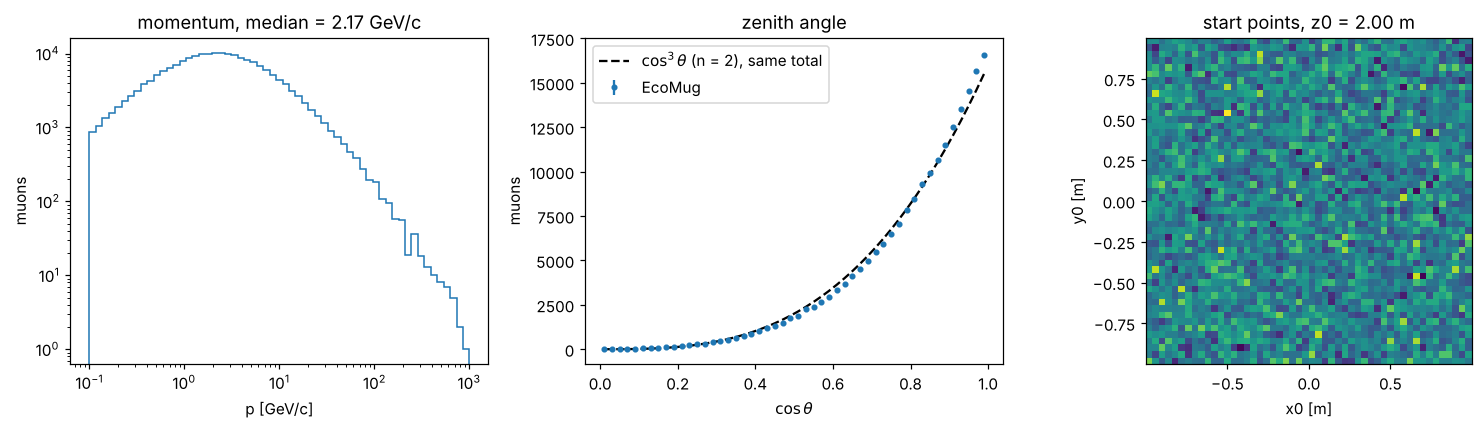

pdg codes: (array([-13,  13], dtype=int32), array([112233,  87767]))   (13 = mu-, -13 = mu+)
all downward: True


In [8]:
pri = run["Primaries"].arrays(library="np")
p_GeV = np.sqrt(pri["px"]**2 + pri["py"]**2 + pri["pz"]**2)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

# Momentum spectrum, log binning
bins = np.logspace(-1, 3, 60)
ax[0].hist(p_GeV, bins=bins, histtype="step")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("p [GeV/c]"); ax[0].set_ylabel("muons")
ax[0].set_title(f"momentum, median = {np.median(p_GeV):.2f} GeV/c")

# Zenith angle. Through a horizontal plane, dN/dcos(theta) ~ cos^(n+1)(theta),
# so cos^3 for the classical n = 2.
c = np.cos(np.radians(pri["theta_deg"]))
h, edges = np.histogram(c, bins=50, range=(0, 1))
ctr = 0.5 * (edges[1:] + edges[:-1])
ax[1].errorbar(ctr, h, yerr=np.sqrt(h), fmt=".", label="EcoMug")
ax[1].plot(ctr, h.sum() / np.sum(ctr**3) * ctr**3, "k--", label=r"$\cos^3\theta$ (n = 2), same total")
ax[1].set_xlabel(r"$\cos\theta$"); ax[1].set_ylabel("muons"); ax[1].legend()
ax[1].set_title("zenith angle")

# Start points on the generation plane
ax[2].hist2d(pri["x0"] / 1000, pri["y0"] / 1000, bins=50)
ax[2].set_xlabel("x0 [m]"); ax[2].set_ylabel("y0 [m]"); ax[2].set_aspect("equal")
ax[2].set_title(f"start points, z0 = {np.mean(pri['z0'])/1000:.2f} m")

plt.tight_layout(); plt.show()

print(f"pdg codes: {np.unique(pri['pdg'], return_counts=True)}   (13 = mu-, -13 = mu+)")
print(f"all downward: {np.all(pri['pz'] < 0)}")

EcoMug has no fixed exponent $n$. Its distribution is steeper than
$\cos^2\theta$: more muons near the vertical and fewer at large angles than
the dashed line. The effective exponent of the EcoMug flux for
0.1-1000 GeV/c is about 2.3.

## 4. Panel hits: steps, events and energy deposit

The most common mistake is to count rows of `PanelXHits` as muons. One row is
one **step**, of the muon or of one of its secondaries. Most rows come from
low-energy delta electrons, which carry only a small part of the energy.
Always count **events** (`np.unique(eventID)`), and always add the deposits
of one event before applying a threshold.

In [9]:
for i in range(4):
    h = run[f"Panel{i}Hits"].arrays(["eventID", "parentID"], library="np")
    n_rows   = len(h["eventID"])
    n_events = len(np.unique(h["eventID"]))
    n_prim   = np.sum(h["parentID"] == 0)
    print(f"Panel {i} ({LAB_NAME[i]}): {n_rows:7d} rows, {n_events:6d} events, "
          f"{n_rows / n_events:.2f} rows per event, {100 * n_prim / n_rows:.0f} % of the rows from the muon")

Panel 0 (P1):   30134 rows,   3431 events, 8.78 rows per event, 15 % of the rows from the muon
Panel 1 (P0):   31018 rows,   3220 events, 9.63 rows per event, 14 % of the rows from the muon
Panel 2 (P3):   17174 rows,   2167 events, 7.93 rows per event, 16 % of the rows from the muon
Panel 3 (P2):   17976 rows,   1995 events, 9.01 rows per event, 14 % of the rows from the muon


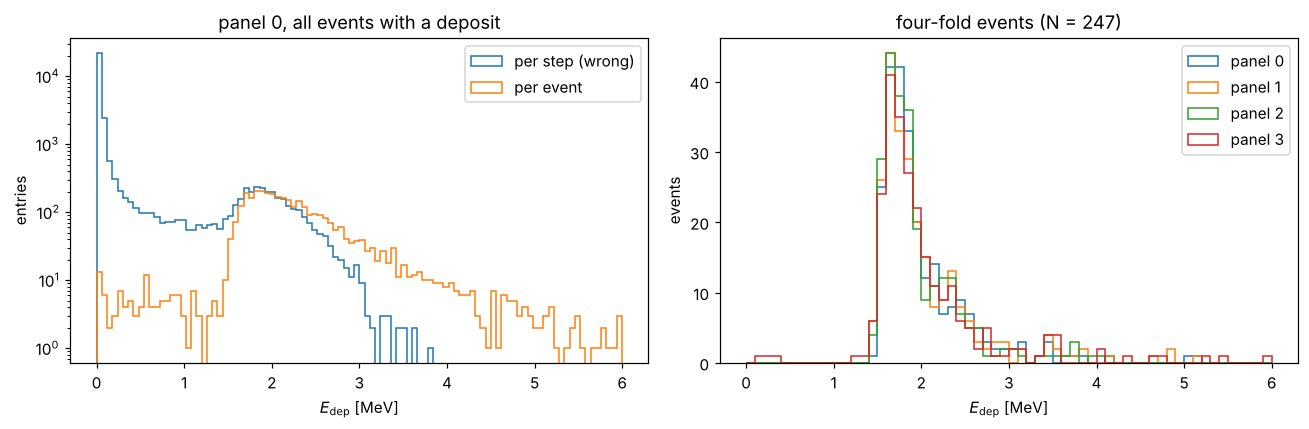

In [10]:
edep = edep_per_event(run, n_gen)        # (n_gen, 4), MeV
sel4 = four_fold(edep)                   # any deposit in all four panels

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Per step vs per event, panel 0
h = run["Panel0Hits"].arrays(["edep"], library="np")
ax[0].hist(h["edep"], bins=100, range=(0, 6), histtype="step", label="per step (wrong)")
ax[0].hist(edep[edep[:, 0] > 0, 0], bins=100, range=(0, 6), histtype="step", label="per event")
ax[0].set_yscale("log"); ax[0].set_xlabel(r"$E_\mathrm{dep}$ [MeV]"); ax[0].set_ylabel("entries")
ax[0].set_title("panel 0, all events with a deposit"); ax[0].legend()

# Four-fold events: all panels
for i in range(4):
    ax[1].hist(edep[sel4, i], bins=60, range=(0, 6), histtype="step", label=f"panel {i}")
ax[1].set_xlabel(r"$E_\mathrm{dep}$ [MeV]"); ax[1].set_ylabel("events")
ax[1].set_title(f"four-fold events (N = {sel4.sum()})"); ax[1].legend()

plt.tight_layout(); plt.show()

### Most probable deposit

The deposit of a muon in 1 cm of plastic follows a Landau distribution. Its
peak (most probable value, MPV) is about 1.7-1.8 MeV. A simple estimate is a
fit of the Moyal function, a good approximation of the Landau shape, around
the peak. `analysis/sim_tables.py` has a more complete Landau x Gauss fit; the
values `E_MPV` used for the thresholds come from there.

In [11]:
def moyal(x, A, mpv, width):
    z = (x - mpv) / width
    return A * np.exp(-0.5 * (z + np.exp(-z)))


mpv_fit = []
for i in range(4):
    h, edges = np.histogram(edep[sel4, i], bins=40, range=(0.6, 3.0))
    ctr = 0.5 * (edges[1:] + edges[:-1])
    ok = h > 0
    popt, pcov = curve_fit(moyal, ctr[ok], h[ok], p0=[h.max(), 1.7, 0.15], sigma=np.sqrt(h[ok]))
    mpv_fit.append(ufloat(popt[1], np.sqrt(pcov[1, 1])))
    print(f"panel {i}: MPV = {mpv_fit[-1]:.3f} MeV   (E_MPV in overburden_analysis.py: {E_MPV[i]:.3f})")

panel 0: MPV = 1.723+/-0.016 MeV   (E_MPV in overburden_analysis.py: 1.718)
panel 1: MPV = 1.681+/-0.019 MeV   (E_MPV in overburden_analysis.py: 1.694)
panel 2: MPV = 1.691+/-0.016 MeV   (E_MPV in overburden_analysis.py: 1.688)
panel 3: MPV = 1.702+/-0.012 MeV   (E_MPV in overburden_analysis.py: 1.711)


## 5. Coincidences and thresholds

The `Coincidence` tree has one row per event. Its flags count **any** deposit,
without threshold:

| Flag | Condition |
| --- | --- |
| `coin_4fold` | all four panels |
| `coin_top` | panels 0 and 1 |
| `coin_bottom` | panels 2 and 3 |
| `coin_outer` | panels 0 and 3 |

The real discriminator has a threshold, so for the comparison with the
measurement the coincidence is built again from the deposits per event.
First check that the rebuilt coincidence without threshold gives the stored
flags:

In [12]:
coin = run["Coincidence"].arrays(library="np")

print("events in Coincidence :", len(coin["eventID"]))
print("coin_4fold (stored)   :", coin["coin_4fold"].sum())
print("4-fold rebuilt, thr 0 :", sel4.sum())
print("identical             :", np.array_equal(coin["coin_4fold"] == 1, sel4))

events in Coincidence : 200000
coin_4fold (stored)   : 247
4-fold rebuilt, thr 0 : 247
identical             : True


In [13]:
# Threshold of half the most probable deposit, one value per panel
thr = 0.5 * E_MPV
sel4_thr = four_fold(edep, thr)
outer_thr = np.all(edep[:, [0, 3]] > thr[[0, 3]], axis=1)

print(f"4-fold, no threshold   : {sel4.sum()}")
print(f"4-fold, 0.5 E_MPV      : {sel4_thr.sum()}")
print(f"outer pair, 0.5 E_MPV  : {outer_thr.sum()}")

4-fold, no threshold   : 247
4-fold, 0.5 E_MPV      : 244
outer pair, 0.5 E_MPV  : 247


**Threshold scan.** Since a muon deposits about 1.7 MeV, the four-fold rate
should hardly change for thresholds well below that. A strong change at small
thresholds would point to events made by low-energy secondaries.

In [14]:
rows = []
for t in [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.1]:
    rows.append(dict(threshold_MeV=t,
                     N_4fold=four_fold(edep, t).sum(),
                     N_outer=np.all(edep[:, [0, 3]] > t, axis=1).sum()))
scan = pd.DataFrame(rows)
scan["R_4fold_Hz"] = scan["N_4fold"] / T_exact
scan

,threshold_MeV,N_4fold,N_outer,R_4fold_Hz
0,0.00,247,251,0.626131
1,0.05,247,251,0.626131
2,0.10,247,251,0.626131
3,0.20,246,250,0.623597
4,0.30,245,249,0.621062
5,0.50,244,247,0.618527
6,0.70,244,247,0.618527
7,0.90,244,247,0.618527
8,1.10,244,247,0.618527


Because the four panels are equal squares on one axis, a straight line
through panels 0 and 3 also crosses panels 1 and 2. The outer two-fold and
the four-fold coincidence therefore differ only by a few events. Those events
are worth a look:

In [15]:
odd = np.where(np.all(edep[:, [0, 3]] > 0, axis=1) & ~sel4)[0]
print(f"{len(odd)} events with panels 0 and 3 but not all four:")
for e in odd[:10]:
    print(f"  event {e:6d}: edep per panel = {np.round(edep[e], 3)} MeV")

4 events with panels 0 and 3 but not all four:
  event   9007: edep per panel = [2.102 1.766 0.    0.335] MeV
  event  17320: edep per panel = [3.331 0.    1.686 1.919] MeV
  event  45696: edep per panel = [1.836 1.636 0.    1.393] MeV
  event  58547: edep per panel = [3.356 0.    0.    1.14 ] MeV


## 6. Rate with uncertainty

With the live time from Section 2:

In [16]:
R_any = rate(sel4.sum(), T_exact)
R_thr = rate(sel4_thr.sum(), T_exact)
print(f"R_4fold, no threshold : {R_any:.3f} Hz")
print(f"R_4fold, 0.5 E_MPV    : {R_thr:.3f} Hz")

# The same with the RunInfo numbers only (Phi * A * N4 / N_gen), as in the README.
# Here the 1-2 % uncertainty of flux_hz_m2 enters as well.
phi_run = ufloat(info["flux_hz_m2"], info["flux_err"])
R_alt = phi_run * area * ufloat(sel4.sum(), np.sqrt(sel4.sum())) / n_gen
print(f"R_4fold with flux_hz_m2: {R_alt:.3f} Hz")

R_4fold, no threshold : 0.626+/-0.040 Hz
R_4fold, 0.5 E_MPV    : 0.619+/-0.040 Hz
R_4fold with flux_hz_m2: 0.626+/-0.041 Hz


The statistical error of a simulated rate is $\sqrt{N_4}/T$: a simulation is
a measurement of length $T$. With $2\times10^5$ muons on a 4 m$^2$ plane,
$T \approx 400$ s, which gives about 250 four-fold events and a 6 % error.
For 1 % you need about 40 times more events.

The simulation has no panel efficiency. To compare with the measurement,
multiply by the product of the four measured efficiencies,
$R_\mathrm{exp} = \varepsilon_0 \varepsilon_1 \varepsilon_2 \varepsilon_3 \, R_\mathrm{sim}$.

## 7. Which particle fired the panels

`parentID == 0` marks the primary particle itself. `primaryID` tells which
primary a step descends from, which matters for CRY, where an event has
several primaries. Two useful checks:

1. In how many four-fold events was a panel fired **only by secondaries**
   (for example a delta electron, while the muon missed that panel)?
2. Are there deposits much later than the first one? The real coincidence
   window is 50 ns, but the simulation adds all deposits of an event,
   whenever they happen (for example the electron from a stopped muon that
   decays).

In [17]:
# Deposit of the primary only, per event and panel
edep_prim = np.zeros((n_gen, 4))
t_first = np.full((n_gen, 4), np.inf)
t_last  = np.full((n_gen, 4), -np.inf)

for i in range(4):
    h = run[f"Panel{i}Hits"].arrays(["eventID", "parentID", "edep", "time"], library="np")
    prim = h["parentID"] == 0
    edep_prim[:, i] = np.bincount(h["eventID"][prim], weights=h["edep"][prim], minlength=n_gen)
    np.minimum.at(t_first[:, i], h["eventID"], h["time"])
    np.maximum.at(t_last[:, i],  h["eventID"], h["time"])

only_secondary = sel4 & np.any(edep_prim == 0, axis=1)
print(f"four-fold events             : {sel4.sum()}")
print(f"... with a panel fired only by secondaries: {only_secondary.sum()} "
      f"({100 * only_secondary.sum() / sel4.sum():.1f} %)")

# Time spread inside the four-fold events (all panels)
spread = t_last[sel4].max(axis=1) - t_first[sel4].min(axis=1)
late = spread > 50.0
print(f"... with a deposit more than 50 ns after the first one: {late.sum()}")
print(f"median time spread: {np.median(spread):.2f} ns")

four-fold events             : 247
... with a panel fired only by secondaries: 13 (5.3 %)
... with a deposit more than 50 ns after the first one: 0
median time spread: 3.03 ns


A relativistic muon needs about 3 ns for the 88.5 cm between panels 0 and 3,
so the median spread should be a few ns.

## 8. Light guides (geometry mode 2)

In mode 2 each module has its scintillator and its PMMA light guide. The
light-guide steps are written to the same `PanelXHits` tree, so the two have
to be separated by position: the scintillator ends at $|x| = 140$ mm and the
guide continues on the $-x$ side (at zenith 0).

`flat_mode2.root` was made with the same seed and the same plane as
`flat_mode0.root`, so event *i* is the same muon in both files. This allows a
comparison event by event.

Note that the `Coincidence` flags in mode 2 count deposits in the guide as
well. In the real detector a muon in the guide gives only Cherenkov light,
which is a much smaller signal (Section 11).

In [18]:
run2  = uproot.open(f"{DATA_DIR}/flat_mode2.root")
info2 = read_run_info(run2)

# Same muons?
pz0 = run["Primaries"].arrays(["pz"], library="np")["pz"]
pz2 = run2["Primaries"].arrays(["pz"], library="np")["pz"]
print("same muons in both files:", np.array_equal(pz0, pz2))

e_sc = edep_per_event(run2, n_gen, region="scint")
e_lg = edep_per_event(run2, n_gen, region="guide")

sel_sc   = four_fold(e_sc)              # scintillators only
sel_both = four_fold(e_sc + e_lg)       # scintillator or guide in every module
coin2 = run2["Coincidence"].arrays(["coin_4fold"], library="np")["coin_4fold"] == 1

print(f"4-fold, mode 0                    : {sel4.sum()}")
print(f"4-fold, mode 2, scintillators only: {sel_sc.sum()}")
print(f"4-fold, mode 2, scint. + guides   : {sel_both.sum()}  (stored flag: {coin2.sum()})")

same muons in both files: True


4-fold, mode 0                    : 247
4-fold, mode 2, scintillators only: 237
4-fold, mode 2, scint. + guides   : 324  (stored flag: 324)


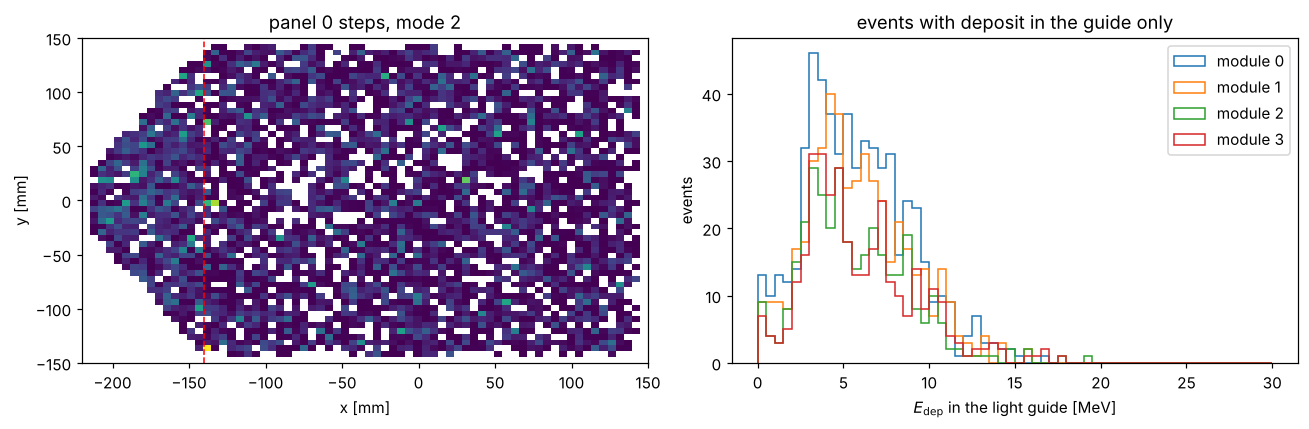

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Where are the steps of panel 0?
h = run2["Panel0Hits"].arrays(["x", "y"], library="np")
ax[0].hist2d(h["x"], h["y"], bins=[70, 56], range=[[-220, 150], [-150, 150]], cmin=1)
ax[0].axvline(-PANEL_HALF, color="r", ls="--", lw=1)
ax[0].set_xlabel("x [mm]"); ax[0].set_ylabel("y [mm]"); ax[0].set_title("panel 0 steps, mode 2")

# Deposit of muons that crossed only the guide of a module
for i in range(4):
    only_guide = (e_lg[:, i] > 0) & (e_sc[:, i] == 0)
    ax[1].hist(e_lg[only_guide, i], bins=60, range=(0, 30), histtype="step", label=f"module {i}")
ax[1].set_xlabel(r"$E_\mathrm{dep}$ in the light guide [MeV]"); ax[1].set_ylabel("events")
ax[1].set_title("events with deposit in the guide only"); ax[1].legend()

plt.tight_layout(); plt.show()

## 9. Zenith scan

`zenith_scan.sh` writes one file per angle, `theta_<angle>.root`. Each file
has its own `RunInfo`, so the table can be built without knowing the scan
settings. The hemisphere surface is used here, so the live time comes from
`live_time_s` (the exact flux of Section 2 is for a horizontal plane only).

In [20]:
def scan_table(folder, threshold=0.0):
    rows = []
    for path in glob.glob(f"{folder}/theta_*.root"):
        theta = float(os.path.basename(path)[len("theta_"):-len(".root")])
        with uproot.open(path) as f:
            inf = read_run_info(f)
            n   = int(inf["n_generated"])
            e   = edep_per_event(f, n)
        n4 = four_fold(e, threshold).sum()
        T  = float(inf["live_time_s"])
        r  = rate(n4, T)
        rows.append(dict(theta=theta, n_gen=n, N_4fold=n4, T_s=T,
                         rate_Hz=r.nominal_value, rate_err=r.std_dev))
    return pd.DataFrame(rows).sort_values("theta").reset_index(drop=True)


scan_df = scan_table(f"{DATA_DIR}/Scan", threshold=0.5 * E_MPV)
scan_df

,theta,n_gen,N_4fold,T_s,rate_Hz,rate_err
0,0.0,200000,135,222.276307,0.607352,0.052273
1,10.0,200000,137,220.462043,0.621422,0.053092
2,20.0,200000,127,221.450348,0.573492,0.050889
3,30.0,200000,101,221.054762,0.456900,0.045463
4,45.0,200000,59,221.991406,0.265776,0.034601
5,60.0,200000,33,221.826051,0.148765,0.025897


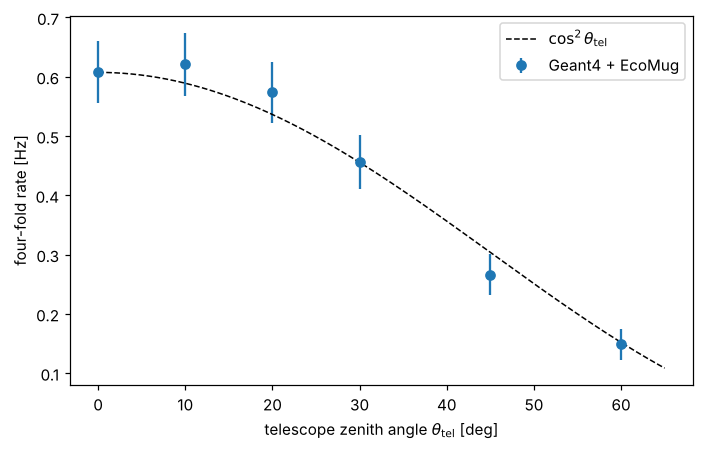

In [21]:
plt.figure(figsize=(6.5, 4.2))
plt.errorbar(scan_df["theta"], scan_df["rate_Hz"], yerr=scan_df["rate_err"], fmt="o", label="Geant4 + EcoMug")

# Rough shape for comparison: cos^2 of the telescope angle, scaled to the first point
th = np.linspace(0, 65, 200)
plt.plot(th, scan_df["rate_Hz"].iloc[0] * np.cos(np.radians(th))**2, "k--", lw=1, label=r"$\cos^2\theta_\mathrm{tel}$")

plt.xlabel(r"telescope zenith angle $\theta_\mathrm{tel}$ [deg]")
plt.ylabel("four-fold rate [Hz]")
plt.legend(); plt.tight_layout(); plt.show()

# Save the table, for example for the comparison with the measurement
# scan_df.to_csv(f"{DATA_DIR}/Scan/scan_table.csv", index=False)

The rate does not follow $\cos^2\theta_\mathrm{tel}$ exactly: the telescope
accepts muons up to about 24 deg from its axis, and the EcoMug flux is not a
pure $\cos^2\theta$. For the angular distribution, fit the model
$R(\theta_\mathrm{tel}) = \varepsilon\, I_0\, G_n(\theta_\mathrm{tel})$ to the
rates rather than dividing by one geometric factor.

## 10. Geometric factor from the isotropic source

The isotropic source (`-g isotropic`) starts muons with directions that follow
the cosine law about the normal of the generation surface. Each area element
then sees an isotropic flux, and the geometric factor of the four-fold
coincidence is

$$G_0 = \pi \, A_\mathrm{gen} \, \frac{N_4}{N_\mathrm{gen}} .$$

The muons have a fixed momentum of 2 GeV/c, so scattering is small and the
result depends on the geometry only. The plane must lie above everything
(here 1.3 m, above the frame at 1.22 m) and be wide enough that no accepted
track starts near its edge. This file has no flux and no live time.

In [22]:
iso      = uproot.open(f"{DATA_DIR}/isotropic_plane.root")
info_iso = read_run_info(iso)
n_iso    = int(info_iso["n_generated"])
A_iso    = float(info_iso["gen_area_m2"])

e_iso = edep_per_event(iso, n_iso)
acc   = four_fold(e_iso)
n4    = acc.sum()

G0 = np.pi * A_iso * ufloat(n4, np.sqrt(n4)) / n_iso * 1e4      # cm^2 sr
print(f"N_gen = {n_iso}, N_4fold = {n4}")
print(f"G0 (Geant4, 1 cm thick panels) = {G0:.1f} cm^2 sr")

N_gen = 2000000, N_4fold = 1197
G0 (Geant4, 1 cm thick panels) = 75.2+/-2.2 cm^2 sr


For comparison, the closed formula of Sullivan (NIM 95, 1971) for two equal
squares of side $a$ and **zero thickness** at distance $Z$:

In [23]:
def G0_sullivan(X, Y, Z):
    # Geometric factor of two equal, aligned rectangles X x Y at distance Z (zero thickness).
    Rx, Ry, R = np.sqrt(X**2 + Z**2), np.sqrt(Y**2 + Z**2), np.sqrt(X**2 + Y**2 + Z**2)
    return (Z**2 * np.log(Rx**2 * Ry**2 / (R**2 * Z**2))
            - 2 * Z * (X * np.arctan(X / Z) + Y * np.arctan(Y / Z))
            + 2 * Y * Rx * np.arctan(Y / Rx) + 2 * X * Ry * np.arctan(X / Ry))


G0_flat = G0_sullivan(28.0, 28.0, 88.5)
print(f"G0, zero thickness, Z = 88.5 cm : {G0_flat:.1f} cm^2 sr")
print(f"Geant4 / zero thickness         : {G0 / G0_flat:.3f}")

G0, zero thickness, Z = 88.5 cm : 73.6 cm^2 sr
Geant4 / zero thickness         : 1.021+/-0.030


The 1 cm thickness makes $G_0$ a few percent larger, because tracks can also
enter or leave a panel through its side faces.

**Acceptance as a function of the zenith angle.** With cosine-law sampling,
$u = \sin^2\theta$ is uniformly distributed. In bins of $u$ the fraction of
accepted muons, times $A_\mathrm{gen}$, is the effective area of the
telescope seen from that angle.

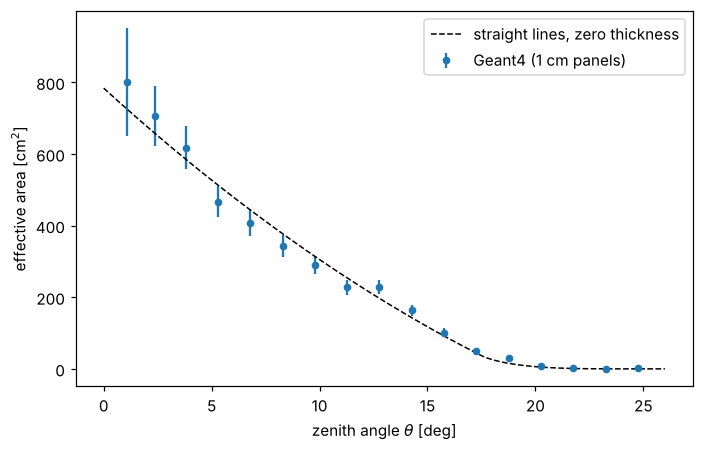

In [24]:
theta_iso = iso["Primaries"].arrays(["theta_deg"], library="np")["theta_deg"]
u = np.sin(np.radians(theta_iso))**2

edges_deg = np.arange(0, 27, 1.5)
edges_u = np.sin(np.radians(edges_deg))**2
n_all, _ = np.histogram(u, bins=edges_u)
n_acc, _ = np.histogram(u[acc], bins=edges_u)
A_eff     = n_acc / n_all * A_iso * 1e4             # cm^2
A_eff_err = np.sqrt(n_acc) / n_all * A_iso * 1e4
ctr = np.degrees(np.arcsin(np.sqrt(0.5 * (edges_u[1:] + edges_u[:-1]))))


def overlap_area(theta_deg, a=28.0, Z=88.5):
    # Overlap of the two outer squares seen along theta, averaged over azimuth (zero thickness).
    s = Z * np.tan(np.radians(theta_deg))
    phi = np.linspace(0, np.pi / 2, 500)
    return np.mean(np.clip(a - s * np.cos(phi), 0, None) * np.clip(a - s * np.sin(phi), 0, None))


th = np.linspace(0, 26, 200)
plt.figure(figsize=(6.5, 4.2))
plt.errorbar(ctr, A_eff, yerr=A_eff_err, fmt="o", ms=4, label="Geant4 (1 cm panels)")
plt.plot(th, [overlap_area(t) for t in th], "k--", lw=1, label="straight lines, zero thickness")
plt.xlabel(r"zenith angle $\theta$ [deg]"); plt.ylabel(r"effective area [cm$^2$]")
plt.legend(); plt.tight_layout(); plt.show()

## 11. Optical photons (`-p`)

With `-p` and geometry mode 2 the scintillation and Cherenkov photons are
tracked to the PMT window. `OpticalSummary` has one row per event, with the
produced and the detected photons per module:

* `prodScint_sc<i>`, `detScint_sc<i>`: scintillation photons in the panel
* `prodCher_lg<i>`, `detCher_lg<i>`: Cherenkov photons in the light guide
* `absBulk<i>`, `absSurf<i>`, `noRindex<i>`: losses

The light-collection efficiency of the scintillator is
`eps_sc = detScint_sc / prodScint_sc`. `analysis/light_collection.py` does the
full analysis of the position scans; here is only the basic reading.

In [25]:
opt_path = f"{DATA_DIR}/optical_beam.root"
if os.path.exists(opt_path):
    opt = uproot.open(opt_path)
    s = opt["OpticalSummary"].arrays(library="np")

    for i in range(4):
        produced = (s[f"prodScint_sc{i}"] + s[f"prodCher_sc{i}"]
                    + s[f"prodCher_lg{i}"] + s[f"prodCher_win{i}"])
        detected = (s[f"detScint_sc{i}"] + s[f"detCher_sc{i}"]
                    + s[f"detCher_lg{i}"] + s[f"detCher_win{i}"])
        lost = s[f"absBulk{i}"] + s[f"absSurf{i}"] + s[f"noRindex{i}"]
        eps_sc = s[f"detScint_sc{i}"] / s[f"prodScint_sc{i}"]
        print(f"module {i}: produced {np.median(produced):7.0f}, detected {np.median(detected):6.0f}, "
              f"eps_sc = {eps_sc.mean():.3f} +- {eps_sc.std(ddof=1) / np.sqrt(len(eps_sc)):.3f}, "
              f"bookkeeping ok: {np.all(produced == detected + lost)}, noRindex = {s[f'noRindex{i}'].sum()}")
else:
    print("no optical file; run make_guide_data.sh without SKIP_OPTICAL")

module 0: produced   16451, detected   2306, eps_sc = 0.139 +- 0.001, bookkeeping ok: True, noRindex = 0
module 1: produced   18649, detected   2568, eps_sc = 0.139 +- 0.001, bookkeeping ok: True, noRindex = 0
module 2: produced   17464, detected   2366, eps_sc = 0.138 +- 0.001, bookkeeping ok: True, noRindex = 0
module 3: produced   16802, detected   2334, eps_sc = 0.139 +- 0.001, bookkeeping ok: True, noRindex = 0


`PhotonHits` (only with `/detector/optics/storePhotons true`) has one row per
detected photon: its origin (0 scintillator, 1 light guide, 2 PMT window),
process (0 scintillation, 1 Cherenkov), wavelength and arrival time.

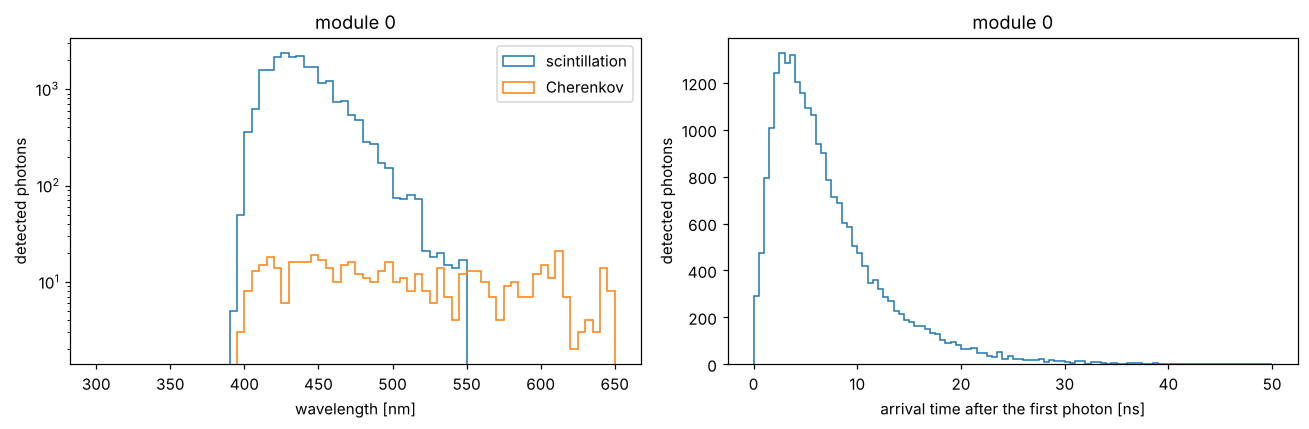

In [26]:
if os.path.exists(opt_path) and "PhotonHits" in opt.keys(cycle=False):
    ph = opt["PhotonHits"].arrays(library="np")
    m0 = ph["module"] == 0
    scint = m0 & (ph["process"] == 0)
    cher  = m0 & (ph["process"] == 1)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(ph["wavelength_nm"][scint], bins=70, range=(300, 650), histtype="step", label="scintillation")
    ax[0].hist(ph["wavelength_nm"][cher],  bins=70, range=(300, 650), histtype="step", label="Cherenkov")
    ax[0].set_xlabel("wavelength [nm]"); ax[0].set_ylabel("detected photons"); ax[0].set_yscale("log")
    ax[0].legend(); ax[0].set_title("module 0")

    # Arrival time relative to the first photon of the same event
    t = ph["time_ns"][m0]; ev = ph["eventID"][m0]
    t0 = np.full(ev.max() + 1, np.inf); np.minimum.at(t0, ev, t)
    ax[1].hist(t - t0[ev], bins=100, range=(0, 50), histtype="step")
    ax[1].set_xlabel("arrival time after the first photon [ns]"); ax[1].set_ylabel("detected photons")
    ax[1].set_title("module 0")
    plt.tight_layout(); plt.show()

## 12. CRY showers

CRY runs need the build option `-DWITH_CRY=ON`. They differ from EcoMug in
three ways:

* An event is a **shower**: `Primaries` has several rows per event, and
  `primaryID` in the hit trees tells which primary a step comes from.
* `n_generated` counts showers, not muons. Muon numbers have to be taken from
  `Primaries` (`pdg == +-13`).
* The live time is CRY's own clock, `RunInfo.live_time_s`, so $R = N_4 / T$.

Set `CRY_FILE` to a CRY output to run the cell; `analysis/soft_component.py`
splits the four-fold events by the kind of primary.

In [27]:
CRY_FILE = f"{DATA_DIR}/cry_showers.root"      # change to your file

if os.path.exists(CRY_FILE):
    cry = uproot.open(CRY_FILE)
    inf = read_run_info(cry)
    n   = int(inf["n_generated"])
    T   = float(inf["live_time_s"])
    pr  = cry["Primaries"].arrays(["eventID", "pdg"], library="np")

    n_mu = np.sum(np.abs(pr["pdg"]) == 13)
    print(f"showers: {n}, particles: {len(pr['pdg'])}, muons: {n_mu}, live time: {T:.1f} s")
    print(f"muon flux through the box top: {n_mu / (T * inf['gen_area_m2']):.1f} m^-2 s^-1")

    e  = edep_per_event(cry, n)
    n4 = four_fold(e, 0.5 * E_MPV).sum()
    print(f"four-fold rate (0.5 E_MPV): {rate(n4, T):.3f} Hz")
else:
    print(f"{CRY_FILE} not found, section skipped")

../build/Guide_Example/cry_showers.root not found, section skipped


## Summary: the rules in short

1. One row of `PanelXHits` is a step. Count events, and add the deposits of an
   event (`np.bincount`) before any threshold.
2. The `Coincidence` flags have no threshold. Build the coincidence again
   from the deposits for comparison with the measurement (0.5 `E_MPV` is the
   usual choice).
3. The rate is $N_4 / T$. For a sky plane, take $T$ from the exact EcoMug
   flux; for a hemisphere or CRY, from `RunInfo.live_time_s`.
4. The statistical error is $\sqrt{N_4}/T$. The simulation has no panel
   efficiency: multiply by $\prod_i \varepsilon_i$ before comparing.
5. Runs with the same seed and the same surface contain the same muons. Use
   this for event-by-event comparisons (mode 0 vs mode 2, with and without
   lead or concrete).
6. In mode 2, steps with $|x| > 140$ mm are in the light guide.
7. Panels 0-3 (top to bottom) are P1, P0, P3, P2 in the lab.